# 7.2 Активации и прямой проход / 激活函数与前向传播
Объекты записываем по строкам: $Z=XW+b$, $A=h(Z)$. В обозначениях кода Z — до активации, A — после неё.
样本按行存放：Z 表示激活前的加权和，A 表示激活后的值。

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"font.size": 11, "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 110})
blue, red = "#356AE6", "#D94F65"
np.set_printoptions(precision=5, suppress=True)

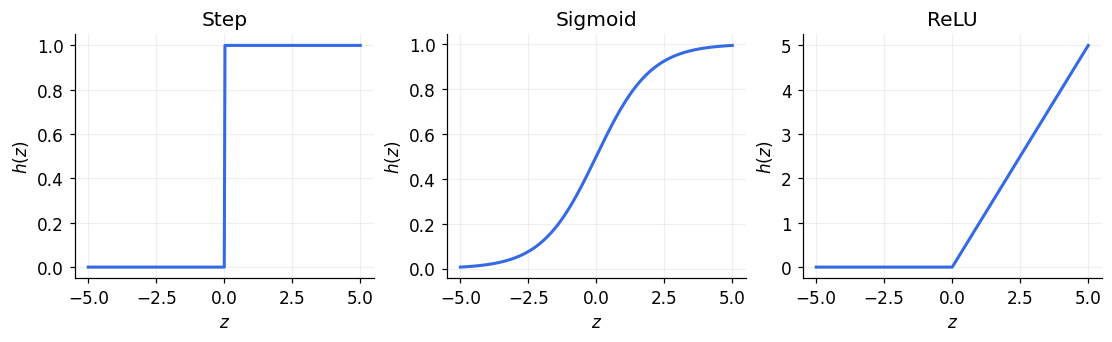

In [2]:
def sigmoid(x):
    return np.exp(-np.logaddexp(0.0, -np.asarray(x)))

def step(x):
    return (np.asarray(x) > 0).astype(int)

def relu(x):
    return np.maximum(0, x)

z = np.linspace(-5, 5, 401)
fig, axes = plt.subplots(1, 3, figsize=(10, 3), layout="constrained")
for ax, fun, name in zip(axes, [step, sigmoid, relu], ["Step", "Sigmoid", "ReLU"]):
    ax.plot(z, fun(z), color=blue, lw=2)
    ax.set(title=name, xlabel="$z$", ylabel="$h(z)$")
    ax.grid(alpha=0.2)
plt.show()

## Матричное произведение / 矩阵乘法
`@` — матричное умножение, `*` — поэлементное. Размеры внутренних осей при `@` должны совпадать.
`@` 是矩阵乘法，`*` 是逐元素乘法。矩阵相乘时内侧维度必须一致。

In [3]:
M = np.array([[1, 2], [3, 4]])
N = np.array([[5, 6], [7, 8]])
print("M @ N:\n", M @ N)
print("M * N:\n", M * N)

X = np.array([[1, 2]])
W = np.array([[1, 3, 5], [2, 4, 6]])
print("X, W, X @ W:", X.shape, W.shape, (X @ W).shape)
print(X @ W)

M @ N:
 [[19 22]
 [43 50]]
M * N:
 [[ 5 12]
 [21 32]]
X, W, X @ W: (1, 2) (2, 3) (1, 3)
[[ 5 11 17]]


## Сеть 2 → 3 → 2 → 1 / 三层前向计算
Параметры заданы вручную. Это вычисление выхода, а не обучение.
以下参数为手动指定，用于演示前向计算，并不是训练结果。

In [4]:
X = np.array([[0.5, 1.0]])
W1 = np.array([[0.2, -0.5, 1.0], [0.7, 0.3, -1.2]])
b1 = np.array([[0.1, -0.2, 0.0]])
W2 = np.array([[0.4, -0.3], [-0.8, 0.6], [0.5, 0.1]])
b2 = np.array([[0.0, 0.2]])
W3 = np.array([[1.0], [-1.5]])
b3 = np.array([[0.3]])

Z1 = X @ W1 + b1
A1 = sigmoid(Z1)
Z2 = A1 @ W2 + b2
A2 = sigmoid(Z2)
Z3 = A2 @ W3 + b3
Y = sigmoid(Z3)
for name, value in [("Z1", Z1), ("A1", A1), ("Z2", Z2),
                    ("A2", A2), ("Z3", Z3), ("Y", Y)]:
    print(name, value.shape, value)

Z1 (1, 3) [[ 0.9  -0.15 -0.7 ]]
A1 (1, 3) [[0.71095 0.46257 0.33181]]
Z2 (1, 2) [[0.08023 0.29744]]
A2 (1, 2) [[0.52005 0.57382]]
Z3 (1, 1) [[-0.04068]]
Y (1, 1) [[0.48983]]


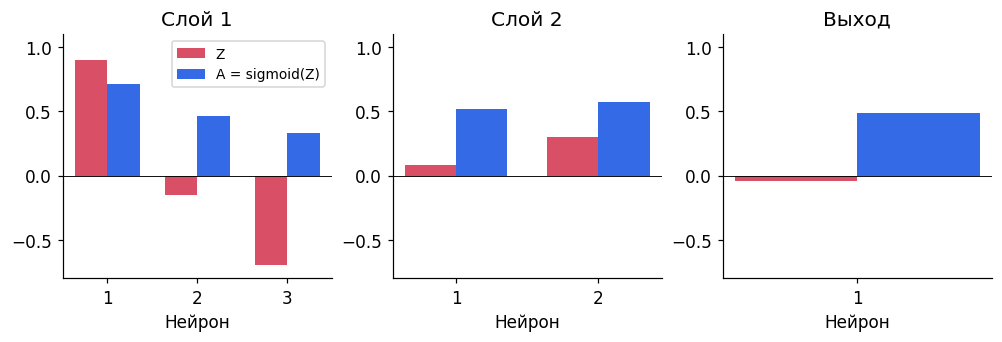

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(9, 3), layout="constrained")
for ax, pre, post, name in zip(axes, [Z1, Z2, Z3], [A1, A2, Y],
                              ["Слой 1", "Слой 2", "Выход"]):
    positions = np.arange(pre.size)
    ax.bar(positions - 0.18, pre.ravel(), 0.36, label="Z", color=red)
    ax.bar(positions + 0.18, post.ravel(), 0.36, label="A = sigmoid(Z)", color=blue)
    ax.set(title=name, xlabel="Нейрон", ylim=(-0.8, 1.1))
    ax.set_xticks(positions, positions + 1)
    ax.axhline(0, color="black", lw=0.6)
axes[0].legend(fontsize=9)
plt.show()

## Несколько объектов за один проход / 一次计算多个样本
Смещение `(1, n)` распространяется на все строки. Результат пакетного вычисления совпадает с вычислением каждой строки отдельно.
偏置 `(1, n)` 会广播到每一行；批量计算与逐个样本计算一致。

In [6]:
def forward(X):
    A1 = sigmoid(X @ W1 + b1)
    A2 = sigmoid(A1 @ W2 + b2)
    return sigmoid(A2 @ W3 + b3)

X_batch = np.array([[0.5, 1.0], [1.0, 0.0], [0.0, 1.0]])
Y_batch = forward(X_batch)
Y_rows = np.vstack([forward(row[None, :]) for row in X_batch])
print("Batch output:\n", Y_batch)
print("Maximum difference:", np.max(np.abs(Y_batch - Y_rows)))

Batch output:
 [[0.48983]
 [0.50503]
 [0.47998]]
Maximum difference: 0.0


## Выход слоя / 输出层
Для неограниченной регрессии можно оставить линейный выход; для бинарного решения использовать sigmoid, для взаимоисключающих классов — softmax.
无界回归可使用线性输出；二分类可使用 sigmoid；互斥多分类可使用 softmax。

In [7]:
def softmax(z):
    shifted = z - np.max(z, axis=-1, keepdims=True)
    exp_z = np.exp(shifted)
    return exp_z / exp_z.sum(axis=-1, keepdims=True)

scores = np.array([[2.0, 1.0, -1.0]])
probabilities = softmax(scores)
print(probabilities)
print("Sum:", probabilities.sum(axis=1))

[[0.70538 0.2595  0.03512]]
Sum: [1.]
